# IND320 Assignment 3

## GitHub and Streamlit app
GitHub repository can be found [Here](https://github.com/ptilrem/ptilrem-D2D-SLapp/tree/main)

Streamlit app can be found [Here](https://ptilrem-d2d-slapp.streamlit.app/)

# Tasks

## Imports

In [31]:
import geopandas as gpd
import pandas as pd
import requests
import matplotlib.pyplot as plt
import numpy as np
from scipy.fft import dct, idct
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram

In [10]:
# Read the regional boundaries from ZIP files
nve_regions = gpd.read_file("../data/NVE_Region.zip")
electricity_regions = gpd.read_file("../data/Budområder.zip")

# Inspect their columns and region identifiers
display(nve_regions.head())
display(electricity_regions.head())

,OBJECTID,REGION,REGIONNAVN,POSTNUMMER,POSTSTED,BESÃKSADR,ADRESSE,geometry
0,1.0,RV,Region Vest,6801,FÃ¸rde,Naustdalsveien 1B,Postboks 53,"POLYGON ((193105.76 6929797.839, 191705.75 692..."
1,2.0,RM,Region Midt-Norge,7030,Trondheim,"Abelsgate 9, Trondheim",Abelsgate 9,"POLYGON ((391250 7388620, 392270 7386790, 3937..."
2,3.0,RN,Region Nord,8514,Narvik,Kongensgate 52-54,Kongensgate 52-54,"POLYGON ((1109096.413 7844647.502, 1105115.343..."
3,4.0,RÃ,Region Ãst,2307,Hamar,Vangsvegen 73,Postboks 4223,"POLYGON ((253748.22 6678130.91, 253645.58 6678..."
4,5.0,RS,Region SÃ¸r,3103,TÃ¸nsberg,Anton Jenssens gate 7,Postboks 2124,"POLYGON ((253748.22 6678130.91, 253917.63 6677..."


,objectid,budomr,globalid,st_area(sh,st_perimet,geometry
0,1.0,NO 1,NaN,6.052902e+10,1.657761e+06,"POLYGON ((337473.63 6970542.97, 337711.9 69703..."
1,2.0,NO 2,NaN,6.875969e+10,1.256473e+06,"POLYGON ((-9833.91 6726499.86, -9836 6726404.0..."
2,3.0,NO 3,NaN,1.042199e+11,1.773323e+06,"POLYGON ((308588.7 7261519.43, 313576.63 72590..."
3,4.0,NO 4,NaN,2.032500e+11,3.385499e+06,"POLYGON ((973920.93 7962739.19, 974922.77 7962..."
4,5.0,NO 5,NaN,3.334870e+10,1.106762e+06,"POLYGON ((101466.43 6881318.54, 101525.43 6881..."


In [11]:
# Combine NVE regions
nve_regions["area"] = nve_regions["OBJECTID"].astype(int).map({
    1: "West",    # RV
    2: "North",   # RM
    3: "North",   # RN
    4: "East",    # RØ
    5: "East"     # RS
})

# Merge the polygons belonging to each area
nve_areas = nve_regions.dissolve(by="area", as_index=False)

display(nve_areas[["area", "geometry"]])

,area,geometry
0,East,"POLYGON ((244204.94 6521981.68, 231754.99 6523..."
1,North,"POLYGON ((522969.98 7381455.32, 520050.96 7378..."
2,West,"POLYGON ((193105.76 6929797.839, 191705.75 692..."


In [15]:
# Use an equal-area coordinate system for random sampling.
nve = nve_areas[["area", "geometry"]].to_crs("EPSG:3035")

el = electricity_regions[["budomr", "geometry"]].rename(
    columns={"budomr": "area"}
).to_crs("EPSG:3035")
el["area"] = el["area"].str.replace(" ", "", regex=False)

# Combine all eight regions into one GeoDataFrame.
regions = gpd.GeoDataFrame(
    pd.concat([nve, el], ignore_index=True),
    geometry="geometry",
    crs="EPSG:3035"
)

# Sample 1,000 points inside each region.
regions["geometry"] = regions.geometry.sample_points(1000, rng=42)

# Separate the points and convert to latitude/longitude.
locations = regions.explode(ignore_index=True).to_crs("EPSG:4326")
locations["latitude"] = locations.geometry.y
locations["longitude"] = locations.geometry.x

# Verify the result.
print("Total locations:", len(locations))
display(locations.groupby("area").size())
display(locations[["area", "latitude", "longitude"]].head())

Total locations: 8000


area
East     1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
North    1000
West     1000
dtype: int64

,area,latitude,longitude
0,East,62.093330,8.284570
1,East,58.770033,5.676368
2,East,60.307476,11.145033
3,East,62.026214,7.679507
4,East,61.264602,8.563117


In [33]:
# Save the sampled region coordinates for use in Streamlit.
region_locations = locations[["area", "latitude", "longitude"]].copy()

region_locations.to_parquet(
    "../data/region_locations.parquet",
    index=False
)

print("Saved locations:", len(region_locations))
display(region_locations.groupby("area").size())

Saved locations: 8000


area
East     1000
NO1      1000
NO2      1000
NO3      1000
NO4      1000
NO5      1000
North    1000
West     1000
dtype: int64

In [18]:
# Download ERA5 weather and average the measurements across sampled locations.
def download_weather(region, start_date, end_date, n_locations=5):
    points = locations[locations["area"] == region].head(n_locations)

    if points.empty:
        raise ValueError(f"Unknown region: {region}")

    params = {
        "latitude": ",".join(points["latitude"].astype(str)),
        "longitude": ",".join(points["longitude"].astype(str)),
        "start_date": start_date,
        "end_date": end_date,
        "hourly": "temperature_2m,precipitation",
        "models": "era5",
        "timezone": "UTC"
    }

    response = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params=params,
        timeout=120
    )
    response.raise_for_status()

    results = response.json()
    if isinstance(results, dict):
        results = [results]

    # Average hourly values across the requested locations.
    frames = [pd.DataFrame(result["hourly"]) for result in results]
    weather = (
        pd.concat(frames)
        .groupby("time", as_index=False)[["temperature_2m", "precipitation"]]
        .mean()
    )
    weather["time"] = pd.to_datetime(weather["time"], utc=True)

    return weather


# Test with five locations in NO3 during 2024.
weather_no3 = download_weather("NO3", "2024-01-01", "2024-12-31")

print("Hourly observations:", len(weather_no3))
display(weather_no3.head())

Hourly observations: 8784


,time,temperature_2m,precipitation
0,2024-01-01 00:00:00+00:00,-9.40,0.02
1,2024-01-01 01:00:00+00:00,-9.44,0.02
2,2024-01-01 02:00:00+00:00,-9.38,0.02
3,2024-01-01 03:00:00+00:00,-9.38,0.02
4,2024-01-01 04:00:00+00:00,-9.28,0.02


In [19]:
# Save the preliminary five-location average for reuse.
weather_no3.to_parquet("../data/weather_NO3_2024_5locations.parquet", index=False)

print("Saved", len(weather_no3), "hourly observations.")

Saved 8784 hourly observations.


In [20]:
# Calculate daily weather values from the hourly ERA5 data.
daily_weather = (
    weather_no3.set_index("time")
    .resample("D")
    .agg({
        "precipitation": "sum",
        "temperature_2m": "mean"
    })
    .reset_index()
)

daily_weather = daily_weather.rename(columns={
    "precipitation": "precipitation_mm",
    "temperature_2m": "temperature_c"
})

print("Daily observations:", len(daily_weather))
display(daily_weather.head())

Daily observations: 366


,time,precipitation_mm,temperature_c
0,2024-01-01 00:00:00+00:00,0.68,-10.060000
1,2024-01-02 00:00:00+00:00,0.46,-13.190833
2,2024-01-03 00:00:00+00:00,0.06,-16.310833
3,2024-01-04 00:00:00+00:00,0.00,-20.486667
4,2024-01-05 00:00:00+00:00,0.30,-20.413333


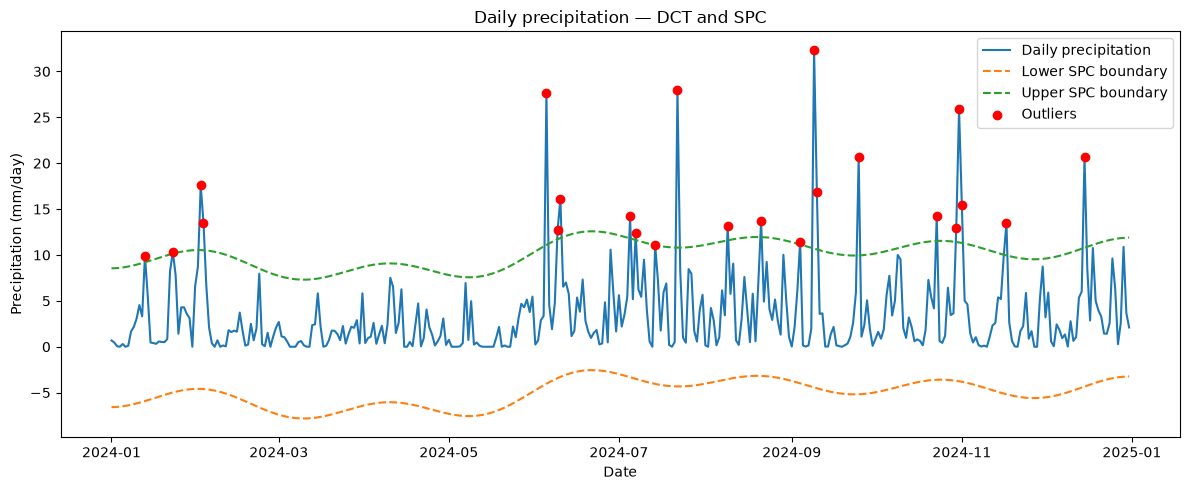

Outliers detected: 23 of 366 days


,time,precipitation_mm
12,2024-01-13 00:00:00+00:00,9.94
22,2024-01-23 00:00:00+00:00,10.32
32,2024-02-02 00:00:00+00:00,17.58
33,2024-02-03 00:00:00+00:00,13.50
156,2024-06-05 00:00:00+00:00,27.62


In [23]:
# Detect precipitation outliers using DCT filtering and robust SPC boundaries.
def plot_precipitation_spc(data, cutoff=12, n_std=3):
    precipitation = data["precipitation_mm"].to_numpy()

    # Remove the lowest DCT frequencies to isolate short-term variations.
    coefficients = dct(precipitation, norm="ortho")
    coefficients[cutoff:] = 0
    trend = idct(coefficients, norm="ortho")
    satv = precipitation - trend

    # Estimate the centre and standard deviation using robust statistics.
    centre = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - centre))

    lower = trend + centre - n_std * sigma
    upper = trend + centre + n_std * sigma

    # Identify observations outside the SPC boundaries.
    mask = (precipitation < lower) | (precipitation > upper)
    outliers = data.loc[mask, ["time", "precipitation_mm"]].copy()

    # Plot precipitation and its boundaries, but not SATV itself.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(data["time"], precipitation, label="Daily precipitation")
    ax.plot(data["time"], lower, "--", label="Lower SPC boundary")
    ax.plot(data["time"], upper, "--", label="Upper SPC boundary")
    ax.scatter(
        data.loc[mask, "time"],
        precipitation[mask],
        color="red",
        label="Outliers",
        zorder=3
    )

    ax.set_title("Daily precipitation — DCT and SPC")
    ax.set_xlabel("Date")
    ax.set_ylabel("Precipitation (mm/day)")
    ax.legend()
    fig.tight_layout()

    return fig, outliers


# Test the analysis using the NO3 weather data for 2024.
fig, outliers = plot_precipitation_spc(daily_weather)

plt.show()
print(f"Outliers detected: {len(outliers)} of {len(daily_weather)} days")
display(outliers.head())

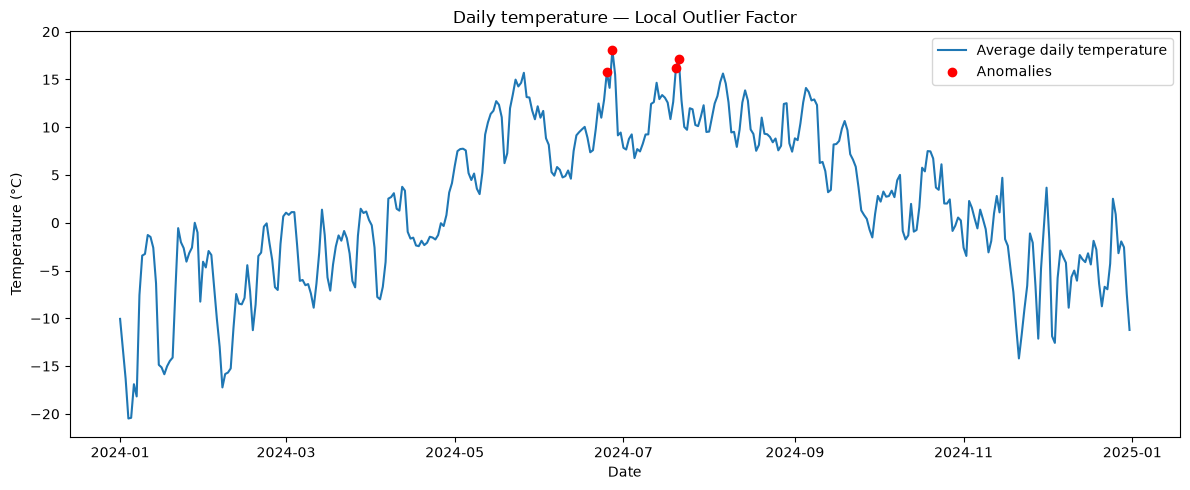

Anomalies detected: 4 of 366 days


,time,temperature_c
176,2024-06-25 00:00:00+00:00,15.741667
178,2024-06-27 00:00:00+00:00,18.102500
201,2024-07-20 00:00:00+00:00,16.245833
202,2024-07-21 00:00:00+00:00,17.180000


In [26]:
# Detect unusual daily temperatures using Local Outlier Factor.
def plot_temperature_lof(data, outlier_fraction=0.01):
    temperatures = data[["temperature_c"]]

    # LOF returns -1 for anomalies and 1 for normal observations.
    lof = LocalOutlierFactor(
        n_neighbors=20,
        contamination=outlier_fraction
    )
    mask = lof.fit_predict(temperatures) == -1

    anomalies = data.loc[mask, ["time", "temperature_c"]].copy()

    # Plot the original temperatures and highlight anomalies.
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(
        data["time"],
        data["temperature_c"],
        label="Average daily temperature"
    )
    ax.scatter(
        data.loc[mask, "time"],
        data.loc[mask, "temperature_c"],
        color="red",
        label="Anomalies",
        zorder=3
    )

    ax.set_title("Daily temperature — Local Outlier Factor")
    ax.set_xlabel("Date")
    ax.set_ylabel("Temperature (°C)")
    ax.legend()
    fig.tight_layout()

    return fig, anomalies


# Test using NO3 weather data for 2024.
fig, anomalies = plot_temperature_lof(daily_weather)

plt.show()
print(f"Anomalies detected: {len(anomalies)} of {len(daily_weather)} days")
display(anomalies)

In [27]:
# Retrieve the weekly reservoir filling data from NVE.
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(url, timeout=90)
response.raise_for_status()

reservoir_df = pd.DataFrame(response.json())

# Select nationwide reservoir statistics.
reservoir_df = reservoir_df[
    (reservoir_df["omrType"] == "NO") &
    (reservoir_df["omrnr"] == 0)
].copy()

# Keep the date and degree of filling.
reservoir_df = reservoir_df.rename(columns={
    "dato_Id": "date_id",
    "fyllingsgrad": "fill_percentage"
})

reservoir_df["date_id"] = pd.to_datetime(reservoir_df["date_id"])
reservoir_df = reservoir_df.sort_values("date_id")

print("Weekly observations:", len(reservoir_df))
print("Date range:", reservoir_df["date_id"].min(), "to", reservoir_df["date_id"].max())

display(reservoir_df[["date_id", "fill_percentage"]].head())

Weekly observations: 1661
Date range: 1995-01-08 00:00:00 to 2026-11-01 00:00:00


,date_id,fill_percentage
9941,1995-01-08,0.603830
9885,1995-01-15,0.578233
9848,1995-01-22,0.558350
9822,1995-01-29,0.530596
9887,1995-02-05,0.502755


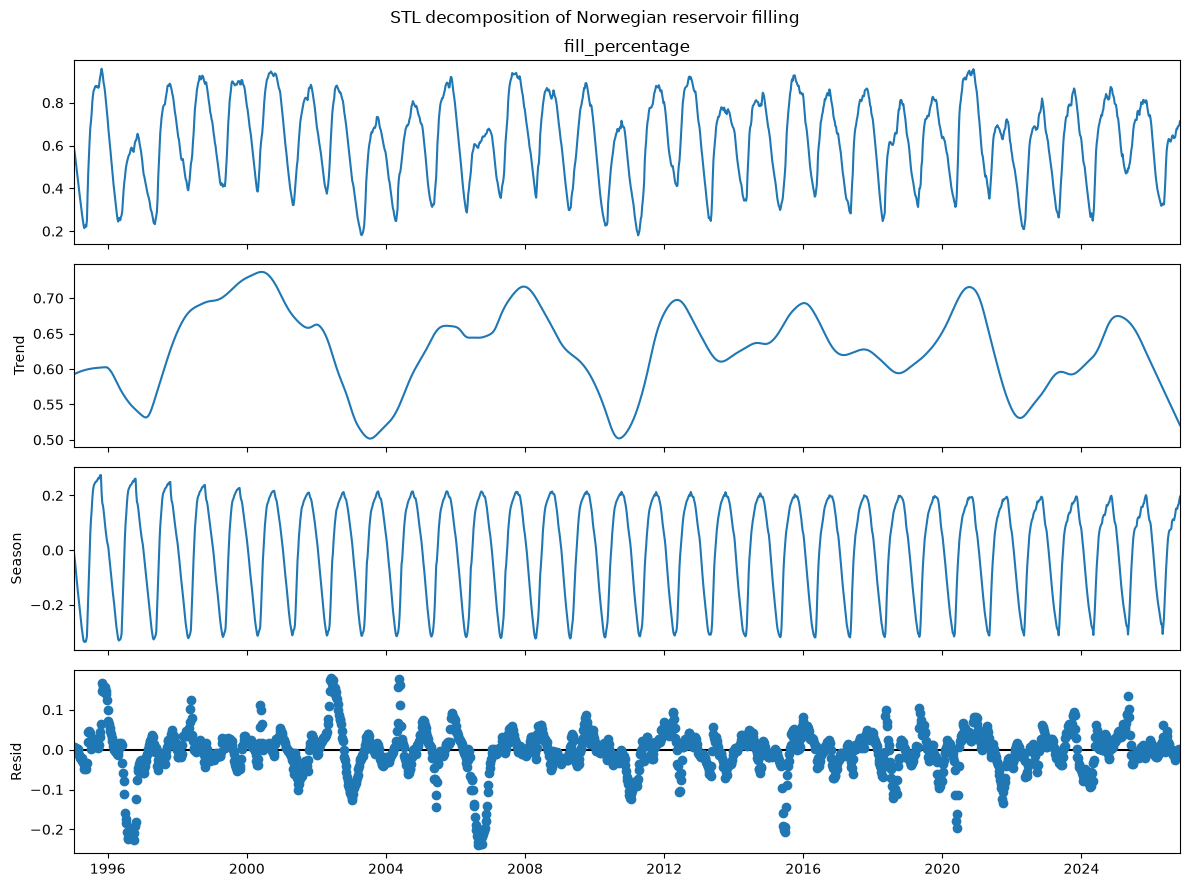

In [30]:
# Decompose weekly reservoir filling into trend, seasonal and residual components.
def plot_stl(data, seasonal=13, trend=101, robust=True):
    # Prepare a regular weekly time series.
    filling = (
        data.set_index("date_id")["fill_percentage"]
        .astype(float)
        .resample("W-SUN")
        .mean()
        .interpolate()
    )

    # Perform STL decomposition with a yearly seasonal cycle.
    result = STL(
        filling,
        period=52,
        seasonal=seasonal,
        trend=trend,
        robust=robust
    ).fit()

    # Plot the original series and its three components.
    fig = result.plot()
    fig.set_size_inches(12, 9)
    fig.suptitle("STL decomposition of Norwegian reservoir filling")
    fig.tight_layout()

    return fig


# Test the STL function.
fig = plot_stl(reservoir_df)
plt.show()

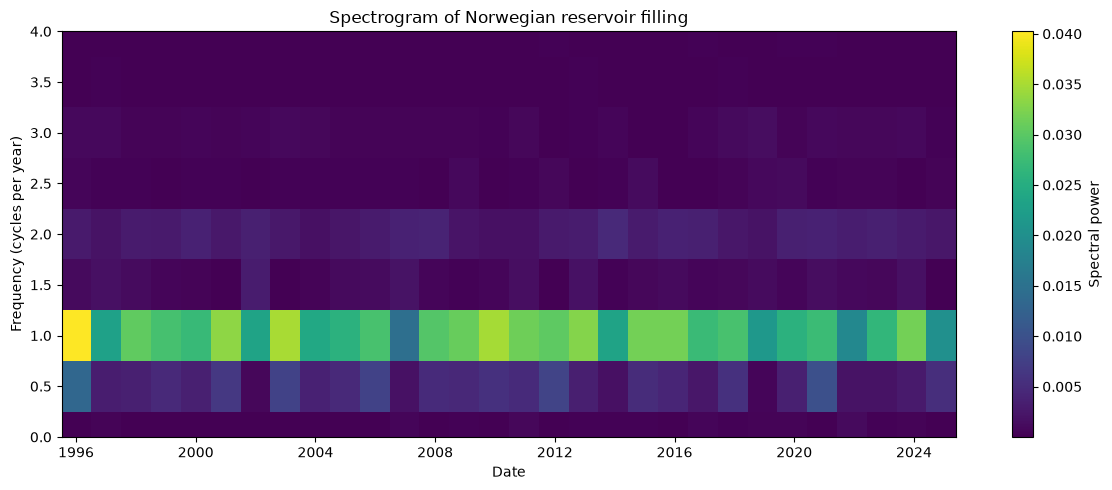

In [32]:
# Plot how the frequencies in weekly reservoir filling change over time.
def plot_spectrogram(data, window_length=104, overlap=52):
    # Prepare the same weekly filling series used for STL.
    filling = (
        data.set_index("date_id")["fill_percentage"]
        .astype(float)
        .resample("W-SUN")
        .mean()
        .interpolate()
    )

    # Calculate the spectrogram using weekly observations.
    frequencies, times, power = spectrogram(
        filling.to_numpy(),
        fs=1,
        nperseg=window_length,
        noverlap=overlap,
        detrend="linear",
        scaling="spectrum"
    )

    # Convert the time and frequency axes to readable units.
    dates = filling.index[0] + pd.to_timedelta(times * 7, unit="D")
    cycles_per_year = frequencies * 52

    fig, ax = plt.subplots(figsize=(12, 5))
    image = ax.pcolormesh(
        dates, cycles_per_year, power, shading="auto"
    )

    ax.set_title("Spectrogram of Norwegian reservoir filling")
    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles per year)")
    ax.set_ylim(0, 4)

    fig.colorbar(image, ax=ax, label="Spectral power")
    fig.tight_layout()

    return fig


# Test the spectrogram.
fig = plot_spectrogram(reservoir_df)
plt.show()